# Transition timing by project

Distance from injection to the selected status transition, with three boxes per project:

- **Non-stable** (grey): every mutant in `data/data_seq` with at least one S→K or K→S transition. The distance is that mutant's transition closest to injection, counted from the bug's newest recorded revision.
- **Attributable** (black): every row in `data/validated.xlsx`.
- **Mutation-specific** (blue): the attributable rows with `mutation_specific` = yes.

Stable mutants, those that only stay S or only stay K, are excluded. Run this notebook from `py-tracker/RQs`.

In [ ]:
%matplotlib inline

import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from openpyxl import load_workbook

HERE = Path.cwd()
DATA_SEQ = HERE / "data" / "data_seq"
WORKBOOK = HERE / "data" / "validated.xlsx"
OUTPUT_STEM = HERE / "transition_timing_by_project_combined"
CROSS_TRANSITIONS = {"S->K", "K->S"}

if not DATA_SEQ.is_dir() or not WORKBOOK.is_file():
    raise FileNotFoundError(
        "Expected data/data_seq and data/validated.xlsx. Run this notebook from py-tracker/RQs."
    )

In [2]:
@dataclass(frozen=True)
class NonstableMutant:
    project: str
    nearest_transition_distance: int
    normalized_nearest_position: float


@dataclass(frozen=True)
class AttributedMutant:
    project: str
    distance: int
    window: int
    mutation_specific: bool


def load_nonstable(data_directory):
    mutants = []
    for path in sorted(data_directory.glob("*_rq1.json")):
        project = path.stem[:-4].rsplit("-", 1)[0]
        with path.open(encoding="utf-8") as handle:
            data = json.load(handle)
        newest = max(
            (
                int(item["index"])
                for record in data.values()
                for item in record.get("sequence") or []
            ),
            default=0,
        )
        for record in data.values():
            distances = [
                newest - int(transition["to_index"]) + 1
                for transition in record.get("transition_records") or []
                if transition.get("transition") in CROSS_TRANSITIONS
            ]
            if not distances:
                continue
            nearest = min(distances)
            mutants.append(
                NonstableMutant(
                    project=project,
                    nearest_transition_distance=nearest,
                    normalized_nearest_position=(
                        (nearest - 1) / newest if newest > 0 else 0.0
                    ),
                )
            )
    if not mutants:
        raise ValueError("No status-changing mutants in data/data_seq")
    return mutants


def load_attributed(workbook):
    required = {
        "project",
        "bug",
        "direction",
        "mutation_specific",
        "revisions_before_injection",
        "window_revisions",
        "relative_position",
    }
    worksheet = load_workbook(workbook, read_only=True, data_only=True)["data"]
    headers = [cell.value for cell in next(worksheet.iter_rows(min_row=1, max_row=1))]
    missing = required.difference(headers)
    if missing:
        raise ValueError(f"Missing required columns in the workbook: {sorted(missing)}")

    mutants = []
    for row_number, values in enumerate(worksheet.iter_rows(min_row=2, values_only=True), start=2):
        record = dict(zip(headers, values))
        distance = int(record["revisions_before_injection"])
        window = int(record["window_revisions"])
        flag = str(record["mutation_specific"]).strip().lower()
        expected_relative = (window - distance) / (window - 1)
        if not np.isclose(float(record["relative_position"]), expected_relative, atol=5e-5):
            raise ValueError(f"Relative-position mismatch on row {row_number}")
        mutants.append(
            AttributedMutant(
                project=str(record["project"]).strip(),
                distance=distance,
                window=window,
                mutation_specific=flag == "yes",
            )
        )
    if not mutants:
        raise ValueError("No mutant rows in the workbook")
    return mutants

In [3]:
nonstable = load_nonstable(DATA_SEQ)
attributed = load_attributed(WORKBOOK)
specific = [mutant for mutant in attributed if mutant.mutation_specific]

print(f"Non-stable mutants: {len(nonstable)}")
print(f"Attributable mutants: {len(attributed)}")
print(f"Mutation-specific mutants: {len(specific)}")

Non-stable mutants: 3764
Attributable mutants: 357
Mutation-specific mutants: 264


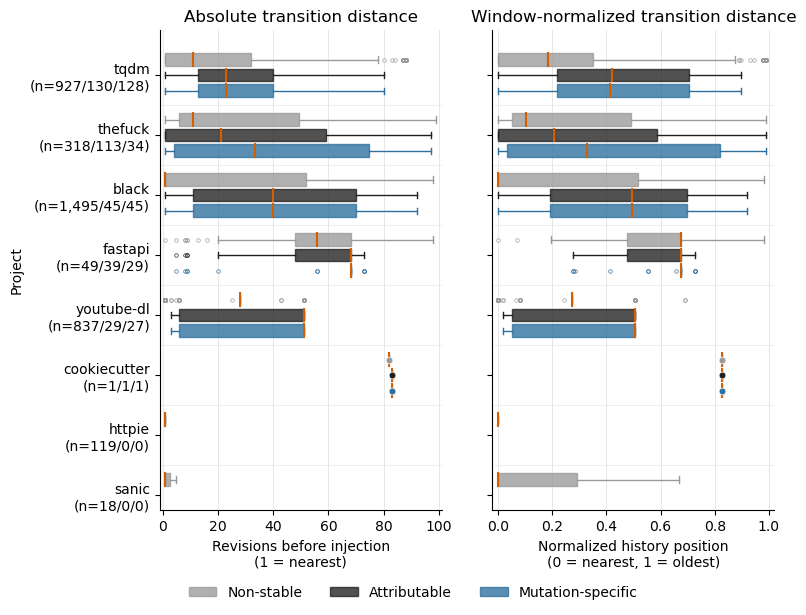

In [ ]:
groups = [
    ("Non-stable", "#9A9A9A", nonstable,
     lambda mutant: float(mutant.nearest_transition_distance),
     lambda mutant: mutant.normalized_nearest_position),
    ("Attributable", "#202020", attributed,
     lambda mutant: float(mutant.distance),
     lambda mutant: (mutant.distance - 1) / (mutant.window - 1)),
    ("Mutation-specific", "#2D6F9E", specific,
     lambda mutant: float(mutant.distance),
     lambda mutant: (mutant.distance - 1) / (mutant.window - 1)),
]
attributed_counts = Counter(mutant.project for mutant in attributed)
nonstable_counts = Counter(mutant.project for mutant in nonstable)
projects = sorted(
    set(attributed_counts) | set(nonstable_counts),
    key=lambda project: (-attributed_counts[project], -nonstable_counts[project], project),
)
positions = np.arange(len(projects), 0, -1, dtype=float)
offsets = [0.26, 0.0, -0.26]

figure, axes = plt.subplots(1, 2, figsize=(7.45, 6.4), sharey=True)
axis_specs = [
    ("Absolute transition distance", "Revisions before injection\n(1 = nearest)", (-1, 101)),
    ("Window-normalized transition distance", "Normalized history position\n(0 = nearest, 1 = oldest)", (-0.02, 1.02)),
]
legend_handles = []
for axis_index, (axis, (title, xlabel, limits)) in enumerate(zip(axes, axis_specs)):
    for (label, color, group, absolute, normalized), offset in zip(groups, offsets):
        metric = absolute if axis_index == 0 else normalized
        data, group_positions = [], []
        for project, position in zip(projects, positions):
            values = [metric(mutant) for mutant in group if mutant.project == project]
            if values:
                data.append(np.asarray(values))
                group_positions.append(position + offset)
        boxes = axis.boxplot(
            data,
            positions=group_positions,
            widths=0.21,
            vert=False,
            patch_artist=True,
            showfliers=True,
            medianprops={"color": "#D55E00", "linewidth": 1.5},
            whiskerprops={"color": color, "linewidth": 1.0},
            capprops={"color": color, "linewidth": 1.0},
            flierprops={
                "marker": "o", "markersize": 2.6, "markerfacecolor": "none",
                "markeredgecolor": color, "markeredgewidth": 0.6, "alpha": 0.8,
            },
            boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.78},
        )
        if axis_index == 0:
            legend_handles.append((boxes["boxes"][0], label))
        for position, values in zip(group_positions, data):
            if len(values) == 1:
                axis.scatter(values, [position], s=24, color=color, edgecolors="#FFFFFF", linewidths=0.5, zorder=3)
    axis.set_title(title)
    axis.set_xlabel(xlabel)
    axis.set_xlim(*limits)
    axis.grid(axis="x", color="#E3E3E3", linewidth=0.6)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    for boundary in positions[:-1] - 0.5:
        axis.axhline(boundary, color="#EBEBEB", linewidth=0.6, zorder=0)

axes[0].set_yticks(positions)
axes[0].set_yticklabels([
    f"{project}\n(n={nonstable_counts[project]:,}/{attributed_counts[project]}/"
    f"{sum(mutant.project == project for mutant in specific)})"
    for project in projects
])
axes[0].set_ylabel("Project")
figure.legend(
    [handle for handle, _ in legend_handles],
    [label for _, label in legend_handles],
    loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.02),
)
figure.subplots_adjust(left=0.16, right=0.985, top=0.93, bottom=0.18, wspace=0.18)
figure.savefig(OUTPUT_STEM.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(OUTPUT_STEM.with_suffix(".png"), dpi=300, bbox_inches="tight")
plt.show()